**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_015_공식형_분류_항공예약관리

### **온기윙의 <span style="color:darkgreen">노쇼 여부</span> 예측 프로젝트**
---

- 도메인 : 항공 예약 관리
- 목  표 : 예약 승객의 노쇼 여부를 예측하는 인공지능모델 개발
- 수익관리팀은 예약 정보로 노쇼 가능성을 예측해 좌석 운영을 최적화하려 한다.
- 노쇼로 인한 빈 좌석이 늘어 온기윙는 초과예약 전략을 정교하게 설계하려 한다.
- 분석에는 약 2,870건 규모의 예약 건 데이터가 제공된다.
- 모델이 노쇼 여부를 신뢰할 만한 수준으로 예측하면 현업의 대응 비용을 줄일 수 있을 것으로 기대한다.

---

#### **[유의사항]**
- 답안 형태는 두 가지입니다. ① **결과 변수 저장형** — 가이드가 지정한 변수(예: `X_train`, `model`)에 결과를 저장하면 그 변수의 내용으로 채점합니다. ② **정답 입력형** — 코드 셀 **맨 아래** `정답NN`(빈칸이 여럿이면 `정답NN_1`, `정답NN_2`) 변수에 **값만** 입력합니다.
- 맨 위 **자동 채점 준비** 셀을 먼저 실행하면, 문항마다 `채점(번호)` 셀로 바로 ✅/❌ 를 확인하고 맨 끝 `채점()` 셀로 총점을 볼 수 있습니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 온기윙의 데이터로 예약 승객의 노쇼 여부를 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, set_option, read_csv, select_dtypes, mean, groupby, corr, quantile, reset_index, drop, fillna, median, sort_values, mode, sum, duplicated, drop_duplicates, get_dummies, info, Series, idxmax, columns, shape) · seaborn(heatmap) · matplotlib(show, plot, title, xlabel, ylabel, legend) · scikit-learn(train_test_split, StandardScaler, fit_transform, transform, KNeighborsClassifier, fit, DecisionTreeClassifier, feature_importances_, predict, classification_report) · TensorFlow(Keras)(Input, Model, EarlyStopping, compile, fit, Dense, BatchNormalization, RMSprop, history)
- 난이도 : 공식형(중급) (설계 난이도 점수 3.05 / 5)
- 예상 소요 시간 : 약 127분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 항공 예약 관리 (교통·물류)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- row_id                : 행 식별번호
- measured_at           : 측정 일자 (문자열 날짜)
- lead_days             : 예약 리드타임(일)
- fare_krw              : 운임(원)
- bag_kg                : 수하물 중량(kg)
- past_flights          : 최근 2년 탑승 횟수
- change_cnt            : 예약 변경 횟수
- checkin_h             : 체크인 시점(출발 전 시간)
- miles                 : 보유 마일리지(천)
- cabin                 : 좌석 등급
- route                 : 노선 유형
- channel               : 예약 채널
- member                : 회원 구분
- no_show               : 노쇼 여부 (0: Show, 1: NoShow)

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [2]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### **1. pandas로 데이터프레임을 출력할 때 소수점 출력 자릿수를 조절할 수 있습니다. 아래 안내대로 옵션을 설정하십시오.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: pandas(import pandas as pd, set_option) | 난이도: 쉬움 | 예상 시간: 4분</sub>

- pandas를 별칭 `pd` 로 불러오세요
- `display.precision` 옵션 값을 **3** 로 설정하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 코드 셀 맨 아래에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [3]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import pandas as pd

pd.set_option('display.precision', 3)


In [ ]:
# (1) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답01 = 'set_option'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

pandas 전역 옵션을 바꾸는 함수를 떠올려 보세요. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `pd.set_option`. 정답은 10글자이고 첫 글자는 `s` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import pandas as pd

pd.set_o_____('display.precision', 3)

정답01 = 'set_o_____'   # 빈칸에 넣은 단어
```

</details>

### **2. 분석 데이터를 읽은 뒤 수치형 컬럼만 따로 모아 새 CSV 파일로 저장할 계획입니다. 아래 안내대로 처리하십시오.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(read_csv, select_dtypes) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 1번 `pd`
- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - 읽어 올 파일 : data.csv → 데이터프레임 변수명 df_raw
    - df_raw 에서 **수치형 컬럼만** 선택해 변수 `num_df` 에 보관하세요 (select_dtypes 활용)
    - `num_df` 를 `num_data.csv` 파일로 저장하세요 (행 번호(인덱스)는 저장하지 않도록 index=False)
- **[정답02]** 저장한 `num_df` 의 **컬럼 개수**는 몇 개인가요?
- 답안 : **[정답02]** 의 값만 코드 셀 맨 아래에 `정답02 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [5]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

df_raw = pd.read_csv('./data.csv')
num_df = df_raw.select_dtypes(include='number')
num_df.to_csv('./num_data.csv', index=False)

num_df.shape[1]

9

In [ ]:
# (2) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답02 = 9

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

수치형 컬럼만 고른 뒤 CSV 로 내보내는 메서드를 쓰세요. 저장한 num_df 의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `select_dtypes`, `to_csv`, `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df_raw = pd.read_csv('./data.csv')
num_df = df_raw.select_dtypes(include='number')
num_df.to_csv('./num_data.csv', index=False)

# [정답02] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
num_df.shape[__]
```

</details>

### **3. 노선 유형(route) 별로 예약 변경 횟수(change_cnt)의 특성을 비교할 계획입니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(mean, groupby) | 난이도: 쉬움 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 노선 유형(route) 별 예약 변경 횟수(change_cnt)의 **평균** 을 구해 변수 `grp` 에 담으세요
    - 대상 데이터프레임 : df_raw
- 아래 코드 셀의 빈칸 `< blank03_1 >`, `< blank03_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `정답03_1`, `정답03_2` 변수에 각각 저장하세요
    - 예시) 정답03_0 = 'data'
- 배점 : 5점

---

In [6]:
# (코드 셀) 코드의 빈칸(< blank >)을 채우고, 맨 아래 정답 변수에 빈칸의 내용을 입력한 뒤 실행하세요

grp = df_raw.groupby('route')['change_cnt'].mean()
grp


,change_cnt
route,
국내선,0.401
동남아,0.481
미주,0.506
유럽,0.423
일본,0.475


In [ ]:
# (3) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답03_1 = 'groupby'
정답03_2 = 'mean'

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

범주별로 묶어서 하나의 통계량을 구하는 패턴입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `groupby`, `mean`. 정답은 7글자이고 첫 글자는 `g` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
grp = df_raw.grou___('route')['change_cnt'].me__()
grp

정답03_1 = 'grou___'   # 빈칸 1에 넣은 단어
정답03_2 = 'me__'   # 빈칸 2에 넣은 단어
```

</details>

### **4. 선택한 수치형 변수들의 상관관계를 히트맵으로 확인하려 합니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: pandas(corr) · seaborn(heatmap) · matplotlib(show) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 대상 데이터프레임 : df_raw
- 대상 변수 : miles, change_cnt, past_flights, checkin_h, fare_krw
- 상관계수 행렬을 구한 뒤 seaborn heatmap 으로 시각화하세요
- 상관계수 값을 표시(annot=True)하고, 색상 팔레트(cmap)는 'YlGnBu' 로 설정하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 코드 셀 맨 아래에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

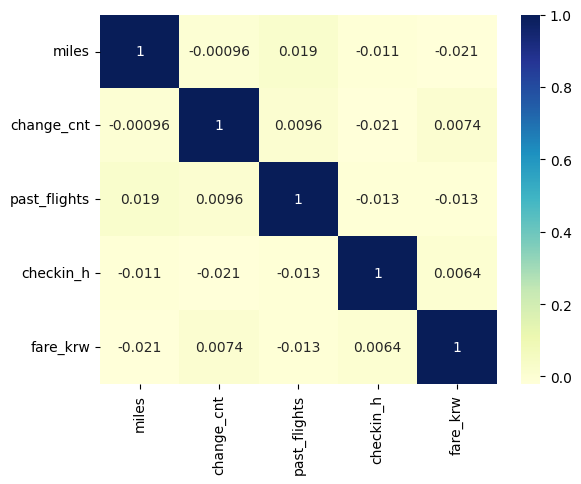

In [7]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.heatmap(df_raw[['miles', 'change_cnt', 'past_flights', 'checkin_h', 'fare_krw']].corr(), annot=True, cmap='YlGnBu')
plt.show()


In [ ]:
# (4) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답04 = 'corr'

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

상관계수 행렬을 색으로 표현하는 그래프입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `.corr()`, `sns.heatmap`. 정답은 4글자이고 첫 글자는 `c` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(df_raw[['miles', 'change_cnt', 'past_flights', 'checkin_h', 'fare_krw']].co__(), annot=True, cmap='YlGnBu')
plt.show()

정답04 = 'co__'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 예약 리드타임(일)(lead_days) 컬럼의 이상치를 IQR 기준으로 제거하고자 합니다. 다음 지침에 따라 처리하십시오.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, reset_index, drop) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 다음 지침에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_raw
    - 사분위수(Q1, Q3)와 IQR 을 산출하세요
    - lower_fence = Q1 - 1.5 x IQR, upper_fence = Q3 + 1.5 x IQR 로 정의하세요
    - lead_days 이(가) 두 fence 밖에 있는 행을 삭제하세요
    - 식별자 컬럼 row_id 도 삭제하고 인덱스를 0부터 다시 매겨 df_clean 에 담으세요
- **[결과 변수]** 결과는 반드시 `df_clean` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df_clean.shape)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [13]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

q1 = df_raw['lead_days'].quantile(0.25)
q3 = df_raw['lead_days'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

is_out = (df_raw['lead_days'] > upper_fence) | (df_raw['lead_days'] < lower_fence)
df_clean = df_raw[~is_out].drop(columns=['row_id']).reset_index(drop=True)

print(df_clean.shape)

(2698, 13)


In [16]:
# (5) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
(2698, 13)

(2698, 13)

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

분위수로 fence 를 계산하고, 범위 밖 여부를 불리언으로 만든 뒤 반대로 선택합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `quantile`, `drop`, `reset_index`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `df_clean` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
q1 = df_raw['lead_days'].quantile(0.25)
q3 = df_raw['lead_days'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

is_out = (df_raw['lead_days'] > upper_fence) | (df_raw['lead_days'] < lower_fence)
df_clean = df_raw[~is_out].drop(columns=['row_id']).reset_index(drop=True)

# [df_clean] 결과 확인 (LMS 에는 이 출력값을 입력)
print(df_clean.shape)
```

</details>

### **6. 날짜 순서가 있는 데이터에서는 결측치를 이웃한 시점의 값으로 채우는 방법을 쓸 수 있습니다. 제시된 가이드에 맞춰 처리하십시오.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(reset_index, fillna, median, sort_values) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 5번 `df_clean`
- 다음 지침에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_clean (결과를 df_filled 에 저장)
    - measured_at 컬럼(문자열 날짜, 사전순이 곧 시간순)으로 오름차순 정렬하고 인덱스를 0부터 다시 매기세요
    - 수치형 결측 컬럼(fare_krw, bag_kg)은 바로 **앞**(이전) 행의 값(ffill)으로 채우세요
    - 맨 앞(또는 맨 뒤)이라 여전히 남은 결측치는 해당 컬럼의 중앙값으로 채우세요
    - 범주형 결측 컬럼(route)은 최빈값으로 채우세요
- **[결과 변수]** 결과는 반드시 `df_filled` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df_filled.shape)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [14]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

df_filled = df_clean.sort_values('measured_at').reset_index(drop=True)
df_filled[['fare_krw', 'bag_kg']] = df_filled[['fare_krw', 'bag_kg']].ffill()
df_filled['fare_krw'] = df_filled['fare_krw'].fillna(df_filled['fare_krw'].median())
df_filled['bag_kg'] = df_filled['bag_kg'].fillna(df_filled['bag_kg'].median())
df_filled['route'] = df_filled['route'].fillna(df_filled['route'].mode()[0])

print(df_filled.shape)

(2698, 13)


In [17]:
# (6) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
(2698, 13)

(2698, 13)

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

날짜순으로 정렬한 뒤, 이웃 값으로 채우는 메서드를 쓰고 남은 결측을 대표값으로 채웁니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `sort_values`, `ffill`, `fillna`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `df_filled` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
df_filled = df_clean.sort_values('measured_at').reset_index(drop=True)
df_filled[['fare_krw', 'bag_kg']] = df_filled[['fare_krw', 'bag_kg']].ffill()
df_filled['fare_krw'] = df_filled['fare_krw'].fillna(df_filled['fare_krw'].median())
df_filled['bag_kg'] = df_filled['bag_kg'].fillna(df_filled['bag_kg'].median())
df_filled['route'] = df_filled['route'].fillna(df_filled['route'].mode()[0])

# [df_filled] 결과 확인 (LMS 에는 이 출력값을 입력)
print(df_filled.shape)
```

</details>

### **7. 데이터에 완전히 동일한 행이 중복되어 있으면 모델이 편향될 수 있습니다. 중복 데이터를 처리하세요.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(sum, reset_index, duplicated, drop_duplicates) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 6번 `df_filled`
- 대상 데이터프레임 : df_filled
- `duplicated()` 로 중복 행의 개수를 구해 변수 `dup_count` 에 저장하고, `drop_duplicates()` 로 중복 행을 제거한 뒤 인덱스를 0부터 다시 매겨 df_filled 에 보관하세요
- 남은 문자열 컬럼 measured_at, cabin, route, channel, member 을(를) get_dummies(drop_first=True)로 인코딩해 df_final 에 보관하세요
- **[결과 변수]** 결과는 반드시 `df_final` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df_final.shape)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [18]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

import pandas as pd

dup_count = df_filled.duplicated().sum()
print('중복 행 개수:', dup_count)
df_filled = df_filled.drop_duplicates().reset_index(drop=True)

df_final = pd.get_dummies(data=df_filled, columns=['measured_at', 'cabin', 'route', 'channel', 'member'], drop_first=True)
df_final.info()

print(df_final.shape)

중복 행 개수: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2682 entries, 0 to 2681
Columns: 1026 entries, lead_days to member_최우수
dtypes: bool(1018), float64(7), int64(1)
memory usage: 2.8 MB
(2682, 1026)


In [ ]:
# (7) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

(2682, 1026)


<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

중복 여부를 불리언으로 구해 합계를 센 뒤, 중복을 제거합니다. 남은 문자열 컬럼을 모두 0/1 컬럼으로 바꿉니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `duplicated`, `drop_duplicates`, `reset_index`, `pd.get_dummies`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `df_final` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
import pandas as pd

dup_count = df_filled.duplicated().sum()
print('중복 행 개수:', dup_count)
df_filled = df_filled.drop_duplicates().reset_index(drop=True)

df_final = pd.get_dummies(data=df_filled, columns=['measured_at', 'cabin', 'route', 'channel', 'member'], drop_first=True)
df_final.info()

# [df_final] 결과 확인 (LMS 에는 이 출력값을 입력)
print(df_final.shape)
```

</details>

### **8. 훈련과 검증 데이터셋을 분리하고, 검증 레이블의 분포를 확인하고자 합니다.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 7번 `df_final`
- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_final
    - 노쇼 여부(no_show) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 지정하세요
    - 결과를 재현할 수 있게 random_state 값을 7 로 지정하세요
    - 데이터를 훈련 65 : 검증 35 로 분할합니다 (test_size=0.35)
    - train_test_split 함수(scikit-learn)로 나누세요
    - 반환값을 담을 변수 : X_train(훈련 피처), X_valid(검증 피처), y_train(훈련 레이블), y_valid(검증 레이블)
- **[결과 변수]** 결과는 반드시 `X_valid` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(len(X_valid))`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [19]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.model_selection import train_test_split

X = df_final.drop('no_show', axis=1)
y = df_final['no_show']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.35, random_state=7)

print(len(X_valid))

939


In [ ]:
# (8) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
939

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `X_valid` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
from sklearn.model_selection import train_test_split

X = df_final.drop('no_show', axis=1)
y = df_final['no_show']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.35, random_state=7)

# [X_valid] 결과 확인 (LMS 에는 이 출력값을 입력)
print(len(X_valid))
```

</details>

### **9. 변수들의 단위(범위) 차이가 모델에 영향을 주지 않도록 스케일링하는 코드가 있습니다. 빈칸을 채워 완성하세요.**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(StandardScaler, fit_transform, transform) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 훈련 데이터(X_train)는 변환 기준을 학습하면서 변환하고, 검증 데이터(X_valid)는 **학습된 기준으로 변환만** 합니다
- 사용할 스케일러 : StandardScaler
- **[정답09]** 스케일링 후 검증 데이터(X_valid)의 **최솟값**을 소수 둘째 자리까지 입력하세요
- 답안 : **[정답09]** 의 값만 코드 셀 맨 아래에 `정답09 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [21]:
# (코드 셀) 아래 코드를 실행하세요 (채점하지 않음)

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)

round(np.min(X_valid), 2)


np.float64(-1.89)

In [ ]:
# (9) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답09 = '-1.89'

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. StandardScaler·MinMaxScaler 같은 스케일러들이 들어 있는 sklearn 하위 모듈 이름입니다. 변환된 검증 데이터 전체에서 최솟값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `StandardScaler`, `fit_transform`, `transform`, `np.min`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.min(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 노쇼 여부(no_show)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. KNN와(과) DecisionTree는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(KNeighborsClassifier, fit, DecisionTreeClassifier) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- KNN 모델을 아래와 같이 만들어 `knn` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_neighbors=11, weights='distance'
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- DecisionTree 모델을 아래와 같이 만들어 `dt` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : max_depth=6, min_samples_leaf=1
    - 난수 시드(random_state) : 42
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `dt`(DecisionTree) 의 **훈련 데이터** 점수 `dt.score(X_train, y_train)` (정확도(accuracy))를 소수점 셋째 자리까지 입력하세요
- 답안 : **[정답10]** 의 값만 코드 셀 맨 아래에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [22]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=11, weights='distance')
knn.fit(X_train, y_train)

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=1, random_state=42)
dt.fit(X_train, y_train)

round(dt.score(X_train, y_train), 3)


0.806

In [ ]:
# (10) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답10 = '0.806'

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 학습된 모델의 score 메서드에 훈련 데이터를 넣고 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `KNeighborsClassifier`, `fit`, `DecisionTreeClassifier`, `score`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=11, weights='distance')
knn.fit(X_train, y_train)

from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=1, random_state=42)
dt.fit(X_train, y_train)

# [정답10] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(dt.score(X_train, y_train), __)
```

</details>

### **11. DecisionTree 모델이 예측에 가장 크게 쓴 변수가 무엇인지 확인할 계획입니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(Series, idxmax, columns) · scikit-learn(feature_importances_) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 8번 `X` · 10번 `dt`
- 학습된 DecisionTree 모델 `dt` 의 변수중요도를 변수명(X.columns)을 인덱스로 하는 Series `fi` 로 만들고, 가장 큰 값의 변수명을 `idxmax()` 로 구해 `top_feature` 에 보관하세요
- **[정답11]** `top_feature` 의 값(변수명)을 작성하세요
- 답안 : **[정답11]** 의 값만 코드 셀 맨 아래에 `정답11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [23]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

fi = pd.Series(dt.feature_importances_, index=X.columns)
top_feature = fi.idxmax()

print(top_feature)


lead_days


In [ ]:
# (11) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답11 = 'lead_days'

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

중요도 배열에 변수 이름 인덱스를 붙여 Series 로 만든 뒤 최댓값의 이름을 구합니다. top_feature 를 출력하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `pd.Series`, `feature_importances_`, `idxmax`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

fi = pd.Series(dt.feature_importances_, index=X.columns)
top_feature = fi.idxmax()

# [정답11] 실행한 결과를 입력하세요
print(top_feature)
```

</details>

### **12. DecisionTree 모델의 성능을 클래스별 정밀도·재현율·F1 이 담긴 보고서로 확인할 계획입니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, classification_report) | 난이도: 어려움 | 예상 시간: 14분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `dt`
- dt 의 best_estimator_ 로 검증데이터(X_valid)를 예측하고, `classification_report(실제값, 예측값, output_dict=True)` 결과를 `report` 에 저장하세요
- **[정답12]** `report['weighted avg']['f1-score']` 값을 소수 둘째 자리까지 기입하세요
- 답안 : **[정답12]** 의 값만 코드 셀 맨 아래에 `정답12 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [24]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.metrics import classification_report

y_pred_dt = dt.predict(X_valid)
report = classification_report(y_valid, y_pred_dt, output_dict=True)

round(report['weighted avg']['f1-score'], 2)


0.71

In [ ]:
# (12) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답12 = 0.71

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

예측한 뒤 실제값과 비교한 클래스별 보고서를 딕셔너리로 만듭니다. report 딕셔너리에서 두 번 인덱싱하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

사용할 도구: `classification_report`, `output_dict`. 가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import classification_report

y_pred_dt = dt.predict(X_valid)
report = classification_report(y_valid, y_pred_dt, output_dict=True)

# [정답12] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
print(round(report['____']['____'], __))
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [25]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(100)

### **13. 노쇼 여부(no_show)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 가이드에 맞춰 신경망을 구성한 뒤 학습까지 진행하세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Input, Model, EarlyStopping, compile) | 난이도: 최상 | 예상 시간: 19분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- 아래 **모델 구조도(topology)** 와 가이드를 함께 참고하세요
- 아래 조건대로 모델을 구현하고 학습하세요
    - tensorflow framework 를 사용하세요
    - Sequential 이 아니라 **함수형 API**로 구성하세요: `Input(shape=(X_train.shape[1],))` 로 입력을 만들고, 각 층을 `층(앞 텐서)` 형태로 이어 붙인 뒤 `Model(inputs=..., outputs=...)` 로 `model` 을 만드세요
    - 은닉층 구성 : Dense × 1 (노드 [64]), activation='selu'
    - 각 Dense 층 뒤에 BatchNormalization 층을 추가하세요
    - Dropout 층은 사용하지 않습니다 / 조기 종료 : EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True) 를 만들어 estop 에 저장하세요
    - 마지막 Dense 층 : 노드 1개 · 활성화 함수 'sigmoid'
    - optimizer 는 문자열이 아니라 RMSprop(learning_rate=0.001) 객체로 지정하고, loss 는 binary_crossentropy, metrics 는 [accuracy] 로 지정해서 모델을 컴파일하세요
    - batch_size 는 32, epochs 는 20 로 학습하고 학습정보는 history 변수에 담으세요 (검증 데이터: X_valid, 검증 레이블)
    - 안내된 내용 외 별도의 파라미터를 입력하지 마세요
- **[결과 변수]** 모델은 `model`, 학습 기록은 `history` 변수에 저장하세요 — 모델 구조(층 수·파라미터 수)와 학습 설정으로 채점합니다
- 확인 : 코드 셀 맨 아래 `print(model.count_params())` 출력값을 LMS 에 입력합니다
- 배점 : 10점

---

**[모델 구조도]**



In [26]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

inputs = Input(shape=(X_train.shape[1],))
x = Dense(64, activation='selu')(inputs)
x = BatchNormalization()(x)
outputs = Dense(1, activation='sigmoid')(x)
model = Model(inputs=inputs, outputs=outputs)

estop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer=RMSprop(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=32,
                    validation_data=(X_valid, y_valid),
                    callbacks=cb_list)

print(model.count_params())

Epoch 1/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.5823 - loss: 0.7843 - val_accuracy: 0.6155 - val_loss: 0.7592
Epoch 2/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7493 - loss: 0.5021 - val_accuracy: 0.6337 - val_loss: 0.7518
Epoch 3/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8308 - loss: 0.3774 - val_accuracy: 0.6422 - val_loss: 0.7993
Epoch 4/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8612 - loss: 0.3083 - val_accuracy: 0.6454 - val_loss: 0.8673
Epoch 5/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8835 - loss: 0.2650 - val_accuracy: 0.6358 - val_loss: 0.9452
Epoch 6/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8996 - loss: 0.2343 - val_accuracy: 0.6347 - val_loss: 1.0243
Epoch 7/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9157 - loss: 0.2102 - val_accuracy: 0.6262 - val_loss: 1.1041
Epoch 8/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9237 - loss: 0.1899 - val_accuracy: 0.6273 - val_lo

In [ ]:
# (13) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
65985

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

입력 텐서를 만들고, 층을 하나씩 앞 텐서에 적용해 이어 붙이세요. 마지막에 Model 로 묶습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Input`, `Dense`, `Dropout`, `Model`, `EarlyStopping`, `model.compile`, `model.fit`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `model` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
inputs = Input(shape=(X_train.shape[1],))
x = Dense(64, activation='selu')(inputs)
x = BatchNormalization()(x)
outputs = Dense(1, activation='sigmoid')(x)
model = Model(inputs=inputs, outputs=outputs)

estop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer=RMSprop(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=32,
                    validation_data=(X_valid, y_valid),
                    callbacks=cb_list)

# [model] 결과 확인 (LMS 에는 이 출력값을 입력)
print(model.count_params())
```

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 Accuracy와(과) 검증 Accuracy의 변화를 그래프로 시각화하십시오.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 13번 `history`
- 그래프 1개 안에 학습 Accuracy·검증 Accuracy 두 선을 모두 그리세요
- 범례를 'train', 'val' 로 표시하세요
- 그래프의 타이틀은 'Model Accuracy' 로, X축 이름은 'Epochs', Y축 이름은 'Accuracy' 로 표시하세요
- 아래 코드 셀의 빈칸 `< blank14_1 >`, `< blank14_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `정답14_1`, `정답14_2` 변수에 각각 저장하세요
    - 예시) 정답14_0 = 'data'
- 배점 : 10점

---

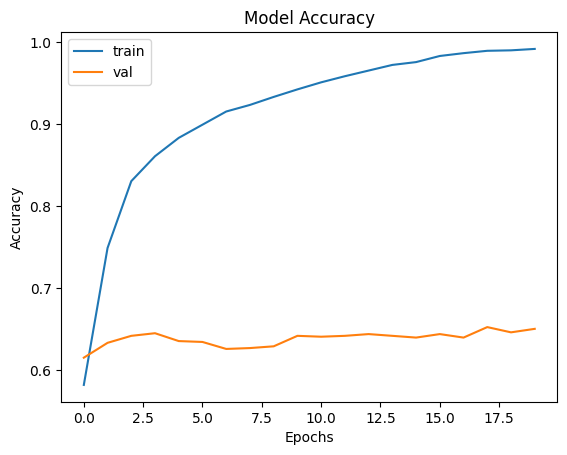

In [28]:
# (코드 셀) 코드의 빈칸(< blank >)을 채우고, 맨 아래 정답 변수에 빈칸의 내용을 입력한 뒤 실행하세요

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['train', 'val'])
plt.show()


In [ ]:
# (14) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답14_1 = 'title'
정답14_2 = 'ylabel'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 그래프 제목을 지정하는 matplotlib 함수입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `plt.plot`, `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`, `plt.show`. 정답은 5글자이고 첫 글자는 `t` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.tit__('Model Accuracy')
plt.xlabel('Epochs')
plt.yla___('Accuracy')
plt.legend(['train', 'val'])
plt.show()

정답14_1 = 'tit__'   # 빈칸 1에 넣은 단어
정답14_2 = 'yla___'   # 빈칸 2에 넣은 단어
```

</details>